# SUNSHIELD v2 — Notebook 4: Evaluation

**Input:** `step3_outputs` (Notebook 3). **Output:** `step4_outputs` (+ zip).

For every k we compare the Actual 0/1 with the Predicted 0/1 (only the evaluated readings, irradiation ≥ 0.2 kW/m²):
- **Version A (plain 0/1)** — main: an alarm is correct if both are 1.
- **Version B (with direction)**: correct only if both are 1 **and** both are on the same side of their expected
  power (both below = power loss, both above). A mismatch counts as "Wrong direction".

The best k is chosen on **Training** (highest F1); Validation and Testing use that same k (Dr. Mai's workflow).

**NEW experiments**
- **Experiment 1 — train on healthy readings or on all readings?** Same rule, same k values, same readings;
  only the LSTM's training data differs.
- **Experiment 2 — why the previous rules gave a low F1** (change from the previous reading; usual power at this time
  of day): how many real outages each rule puts in its ground truth, and how many the predicted line finds.
- **Fault events**: consecutive anomalous readings of one inverter = one event; is each event found?

In [1]:
import os, shutil, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_root():
    for d in ['.', '..', '../..']:
        if os.path.exists(os.path.join(d, 'data', 'raw', 'Plant_1_Generation_Data.csv')):
            return os.path.abspath(d)
    return os.path.abspath('.')

ROOT = find_root()
OUTPUTS = os.path.join(ROOT, 'outputs')

def get_step(name):
    folder = os.path.join(OUTPUTS, name)
    if not os.path.isdir(folder):
        zip_path = os.path.join(OUTPUTS, name + '.zip') if os.path.exists(os.path.join(OUTPUTS, name + '.zip')) else name + '.zip'
        if not os.path.exists(zip_path):
            from google.colab import files
            print(f'Upload {name}.zip'); uploaded = files.upload(); zip_path = list(uploaded)[0]
        shutil.unpack_archive(zip_path, folder, 'zip')
    return folder

STEP3_DIR = get_step('step3_outputs')
OUT_DIR = os.path.join(OUTPUTS, 'step4_outputs')
for sub in ['A_plain', 'B_direction', 'experiments']:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)

k_values = [1.0, 1.5, 2.0, 2.5, 3.0]
splits = ['train', 'val', 'test']
names = {'train': 'Training', 'val': 'Validation', 'test': 'Testing'}

full = {}
for split in splits:
    df = pd.read_csv(os.path.join(STEP3_DIR, f'{split}_with_anomalies.csv'), parse_dates=['DATE_TIME'])
    full[split] = df.sort_values(['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True)
# The evaluation uses the evaluated readings only (irradiation >= 0.2 kW/m²)
data = {s: d[d['EVALUATED'] == 1].reset_index(drop=True) for s, d in full.items()}
for s in splits:
    # direction of each reading: -1 = below its expected power, +1 = above (used in version B)
    data[s]['actual_dir'] = np.sign(data[s]['RESID_ACTUAL_kW']).astype(int)
    data[s]['pred_dir'] = np.sign(data[s]['RESID_PRED_kW']).astype(int)
    print(f'{names[s]:10s}: {len(full[s]):,} readings, {len(data[s]):,} evaluated')

Training  : 36,491 readings, 24,170 evaluated
Validation: 11,968 readings, 7,458 evaluated
Testing   : 10,758 readings, 6,930 evaluated


## Helper functions (as in the previous version; `line` chooses which predicted 0/1 is compared)

In [2]:
def get_flags(df, k, direction, line='pred'):
    a = df[f'actual_anomaly_k{k}'].values
    p = df[f'{line}_anomaly_k{k}'].values
    if direction:
        a = a * df['actual_dir'].values
        p = p * np.sign(df[f'RESID_{line.upper()}_kW']).astype(int).values
    return a, p

def evaluate(df, k, direction=False, line='pred'):
    a, p = get_flags(df, k, direction, line)
    tp = ((a != 0) & (p == a)).sum()
    wrong = ((a != 0) & (p != 0) & (p != a)).sum()   # below vs above (always 0 in version A)
    fp = ((a == 0) & (p != 0)).sum()
    fn = ((a != 0) & (p == 0)).sum()
    tn = ((a == 0) & (p == 0)).sum()
    precision = tp / (tp + fp + wrong) if (tp + fp + wrong) > 0 else 0
    recall = tp / (tp + fn + wrong) if (tp + fn + wrong) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    r = {'k': k, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}
    if direction:
        r['Wrong_direction'] = wrong
    r.update({'Precision': round(precision, 4), 'Recall': round(recall, 4), 'F1': round(f1, 4)})
    return r

def confusion(df, k, direction=False, line='pred'):
    a, p = get_flags(df, k, direction, line)
    classes = [-1, 0, 1] if direction else [0, 1]
    return np.array([[((a == x) & (p == y)).sum() for y in classes] for x in classes])

def plot_cm(ax, cm, title, direction=False):
    labels = ['Below', 'Normal', 'Above'] if direction else ['0', '1']
    n = len(labels)
    ax.imshow(cm, cmap='Blues')
    for i in range(n):
        for j in range(n):
            color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
            ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color=color, fontsize=9)
    ax.set_xticks(range(n)); ax.set_xticklabels(labels, fontsize=8)
    ax.set_yticks(range(n)); ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel('Predicted', fontsize=8); ax.set_ylabel('Actual', fontsize=8)
    ax.set_title(title, fontsize=9); ax.grid(False)

def run_evaluation(direction, folder):
    tag = 'with direction' if direction else 'plain 0/1'
    rows = []
    for split in splits:
        for k in k_values:
            r = evaluate(data[split], k, direction); r['Split'] = names[split]; rows.append(r)
    all_metrics = pd.DataFrame(rows)
    all_metrics = all_metrics[['Split'] + [c for c in all_metrics.columns if c != 'Split']]
    all_metrics.to_csv(f'{folder}/metrics_all_k.csv', index=False)
    print(f'=== Metrics for each k ({tag}) ===')
    print(all_metrics.to_string(index=False))

    for split in splits:
        fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
        for ax, k in zip(axes, k_values):
            plot_cm(ax, confusion(data[split], k, direction), f'{names[split]}, k = {k}', direction)
        plt.suptitle(tag, fontsize=10); plt.tight_layout()
        plt.savefig(f'{folder}/confusion_matrices_{split}.png', dpi=150, bbox_inches='tight'); plt.show()

    train_metrics = all_metrics[all_metrics['Split'] == 'Training'].reset_index(drop=True)
    best_k = train_metrics.loc[train_metrics['F1'].idxmax(), 'k']
    print(f'\nBest k ({tag}) =', best_k, '| Training F1 =', train_metrics['F1'].max())
    with open(f'{folder}/best_k.txt', 'w') as f:
        f.write(f'best_k = {best_k}\n')

    results = []
    for split in splits:
        r = evaluate(data[split], best_k, direction); r['Split'] = names[split]; results.append(r)
    results = pd.DataFrame(results)
    results = results[['Split'] + [c for c in results.columns if c != 'Split']]
    results.to_csv(f'{folder}/results_best_k.csv', index=False)
    print(f'\n=== Results with best k ({tag}) ===')
    print(results.to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6))
    plot_cm(axes[0], confusion(data['val'], best_k, direction), f'Validation, k = {best_k}', direction)
    plot_cm(axes[1], confusion(data['test'], best_k, direction), f'Testing, k = {best_k}', direction)
    plt.suptitle(tag, fontsize=10); plt.tight_layout()
    plt.savefig(f'{folder}/confusion_matrices_best_k_val_test.png', dpi=150, bbox_inches='tight'); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
    for ax, split in zip(axes, splits):
        m = all_metrics[all_metrics['Split'] == names[split]]
        ax.plot(m['k'], m['Precision'], marker='o', label='Precision')
        ax.plot(m['k'], m['Recall'], marker='s', label='Recall')
        ax.plot(m['k'], m['F1'], marker='^', label='F1')
        ax.axvline(best_k, color='grey', linestyle='--', label=f'best k = {best_k}')
        ax.set_title(f'{names[split]} ({tag})'); ax.set_xlabel('k'); ax.set_xticks(k_values)
        ax.set_ylim(0, 1); ax.grid(alpha=0.3)
    axes[0].set_ylabel('Score'); axes[0].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f'{folder}/metrics_vs_k.png', dpi=150, bbox_inches='tight'); plt.show()
    return best_k, results

## Version A — plain 0/1 (main)

=== Metrics for each k (plain 0/1) ===
     Split   k   TP   FP   FN    TN  Precision  Recall     F1
  Training 1.0 7090 2117 1227 13736     0.7701  0.8525 0.8092
  Training 1.5 5151 1580  479 16960     0.7653  0.9149 0.8334
  Training 2.0 4288 1127  201 18554     0.7919  0.9552 0.8659
  Training 2.5 3762  821  114 19473     0.8209  0.9706 0.8895
  Training 3.0 3423  653   58 20036     0.8398  0.9833 0.9059
Validation 1.0 1976  724  282  4476     0.7319  0.8751 0.7971
Validation 1.5 1376  545  149  5388     0.7163  0.9023 0.7986
Validation 2.0 1099  380   66  5913     0.7431  0.9433 0.8313
Validation 2.5  925  293   10  6230     0.7594  0.9893 0.8593
Validation 3.0  825  245    2  6386     0.7710  0.9976 0.8698
   Testing 1.0 1769  727  207  4227     0.7087  0.8952 0.7911
   Testing 1.5 1202  408  129  5191     0.7466  0.9031 0.8174
   Testing 2.0  995  269   35  5631     0.7872  0.9660 0.8675
   Testing 2.5  873  168   23  5866     0.8386  0.9743 0.9014
   Testing 3.0  798  138   14  

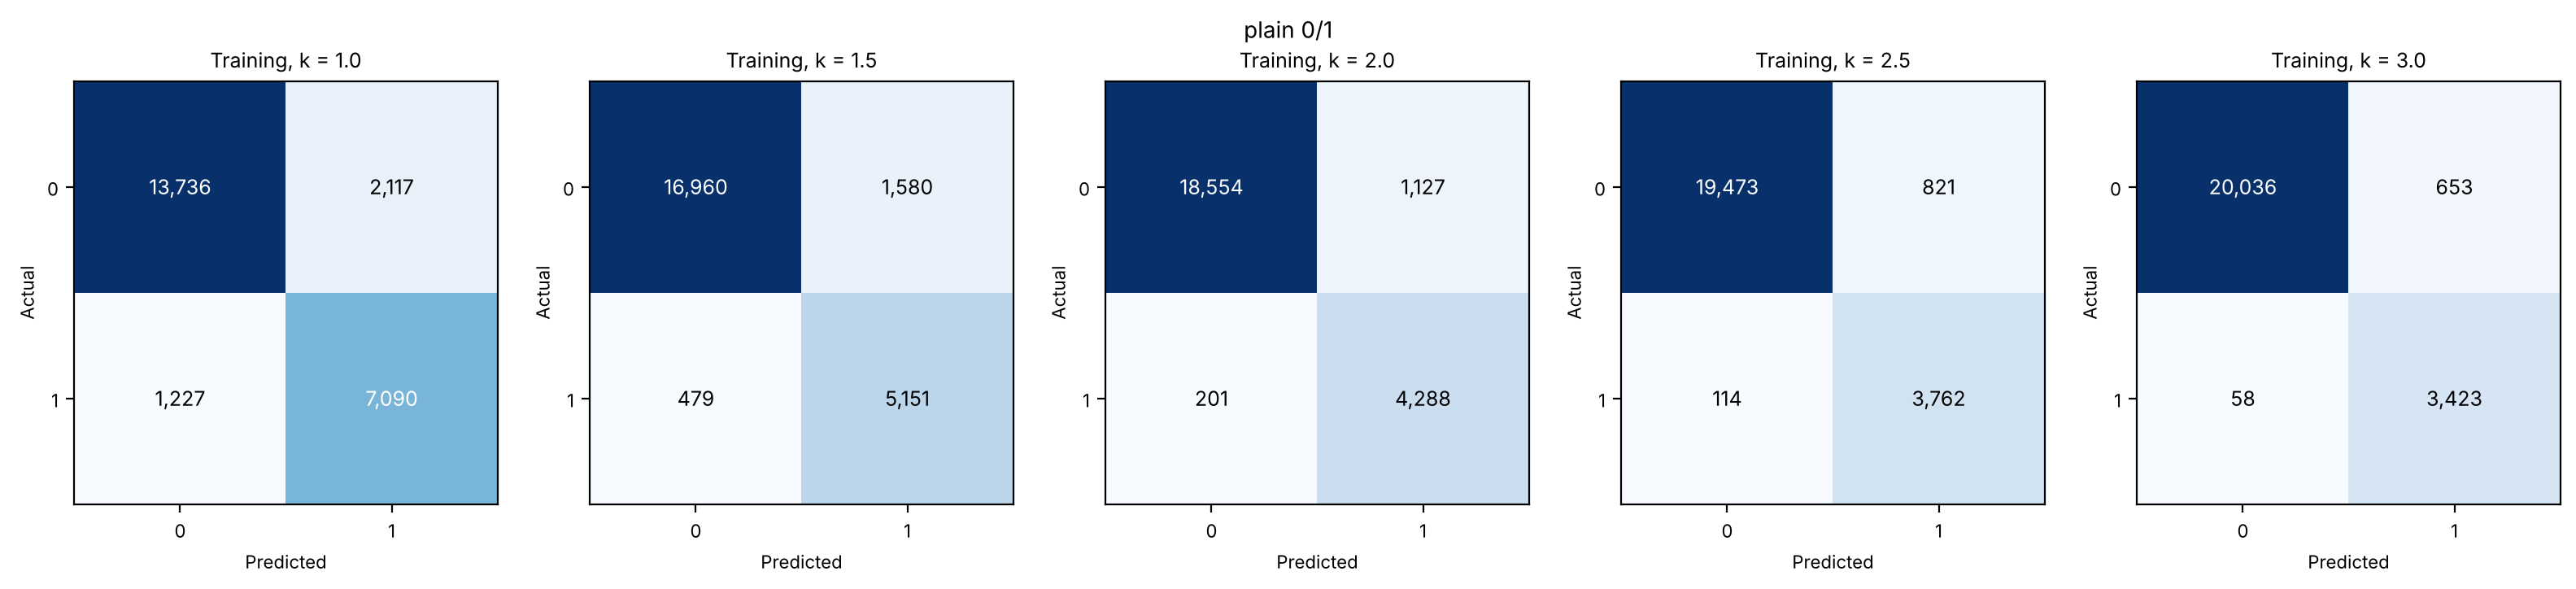

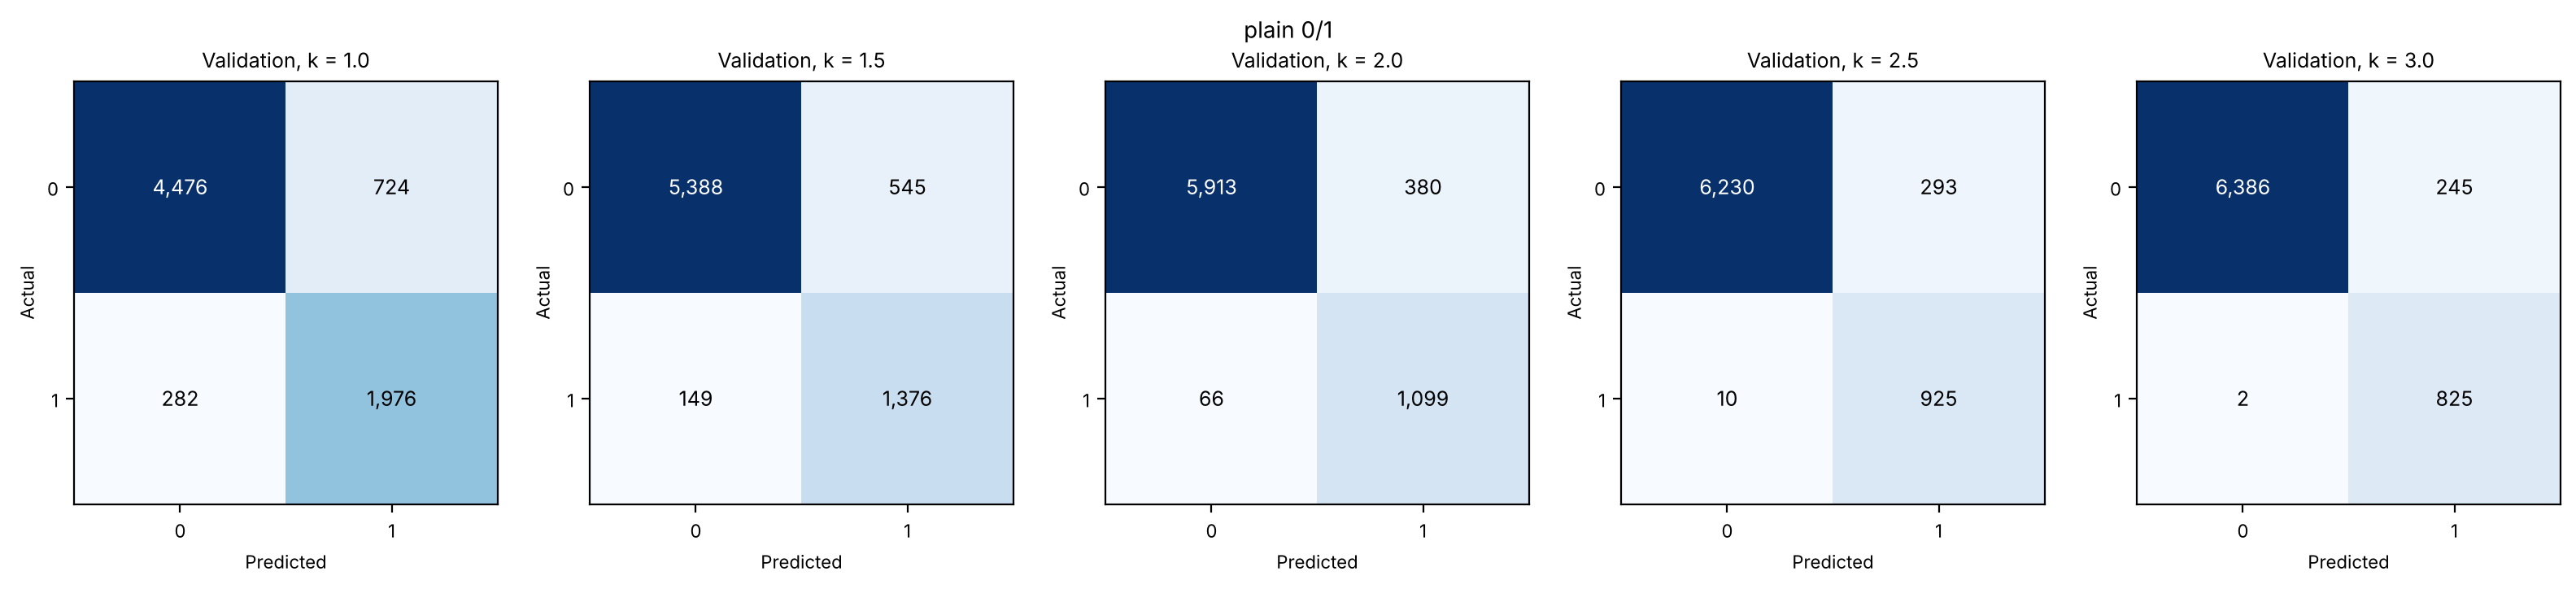

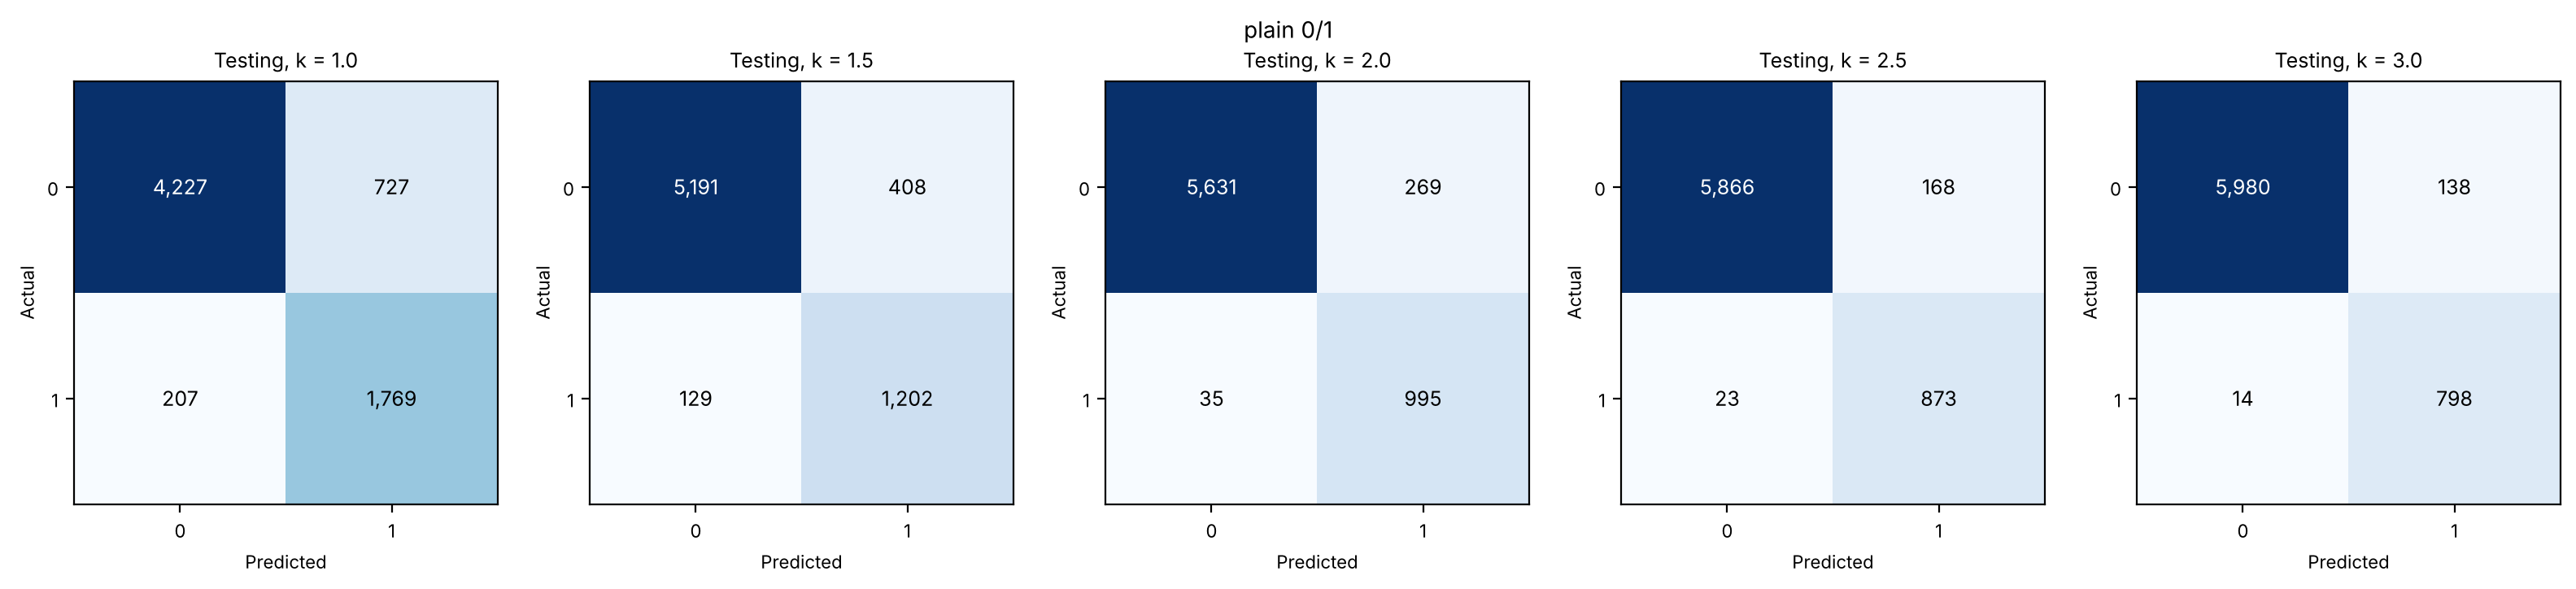


Best k (plain 0/1) = 3.0 | Training F1 = 0.9059

=== Results with best k (plain 0/1) ===
     Split   k   TP  FP  FN    TN  Precision  Recall     F1
  Training 3.0 3423 653  58 20036     0.8398  0.9833 0.9059
Validation 3.0  825 245   2  6386     0.7710  0.9976 0.8698
   Testing 3.0  798 138  14  5980     0.8526  0.9828 0.9130


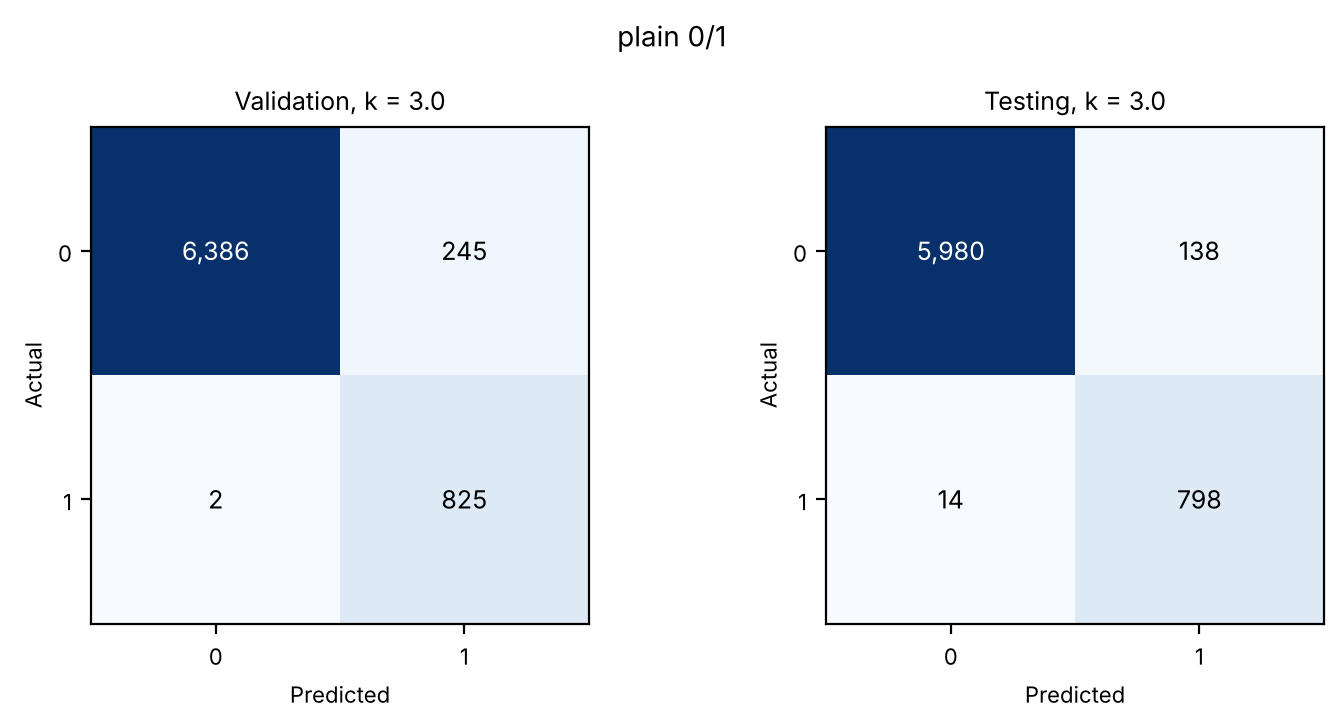

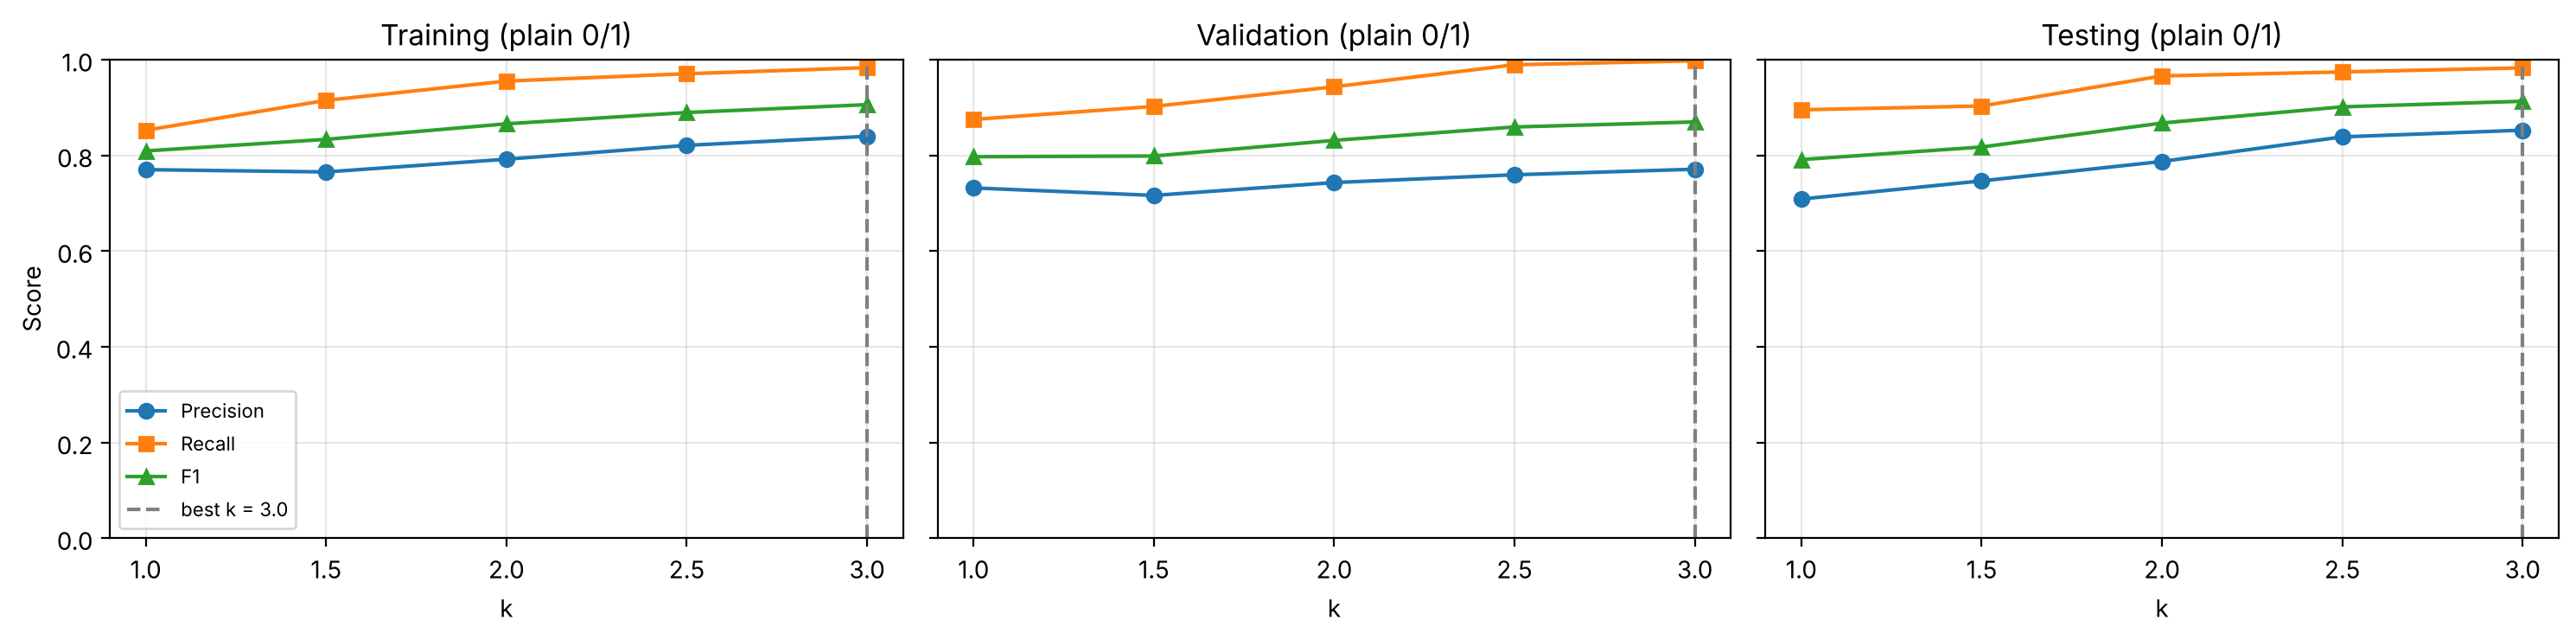

In [3]:
best_k_A, results_A = run_evaluation(direction=False, folder=os.path.join(OUT_DIR, 'A_plain'))

## Version B — with direction (below / above expected power must match)

=== Metrics for each k (with direction) ===
     Split   k   TP   FP   FN    TN  Wrong_direction  Precision  Recall     F1
  Training 1.0 7063 2117 1227 13736               27     0.7671  0.8492 0.8061
  Training 1.5 5151 1580  479 16960                0     0.7653  0.9149 0.8334
  Training 2.0 4288 1127  201 18554                0     0.7919  0.9552 0.8659
  Training 2.5 3762  821  114 19473                0     0.8209  0.9706 0.8895
  Training 3.0 3423  653   58 20036                0     0.8398  0.9833 0.9059
Validation 1.0 1972  724  282  4476                4     0.7304  0.8733 0.7955
Validation 1.5 1376  545  149  5388                0     0.7163  0.9023 0.7986
Validation 2.0 1099  380   66  5913                0     0.7431  0.9433 0.8313
Validation 2.5  925  293   10  6230                0     0.7594  0.9893 0.8593
Validation 3.0  825  245    2  6386                0     0.7710  0.9976 0.8698
   Testing 1.0 1753  727  207  4227               16     0.7023  0.8871 0.7840
   Testi

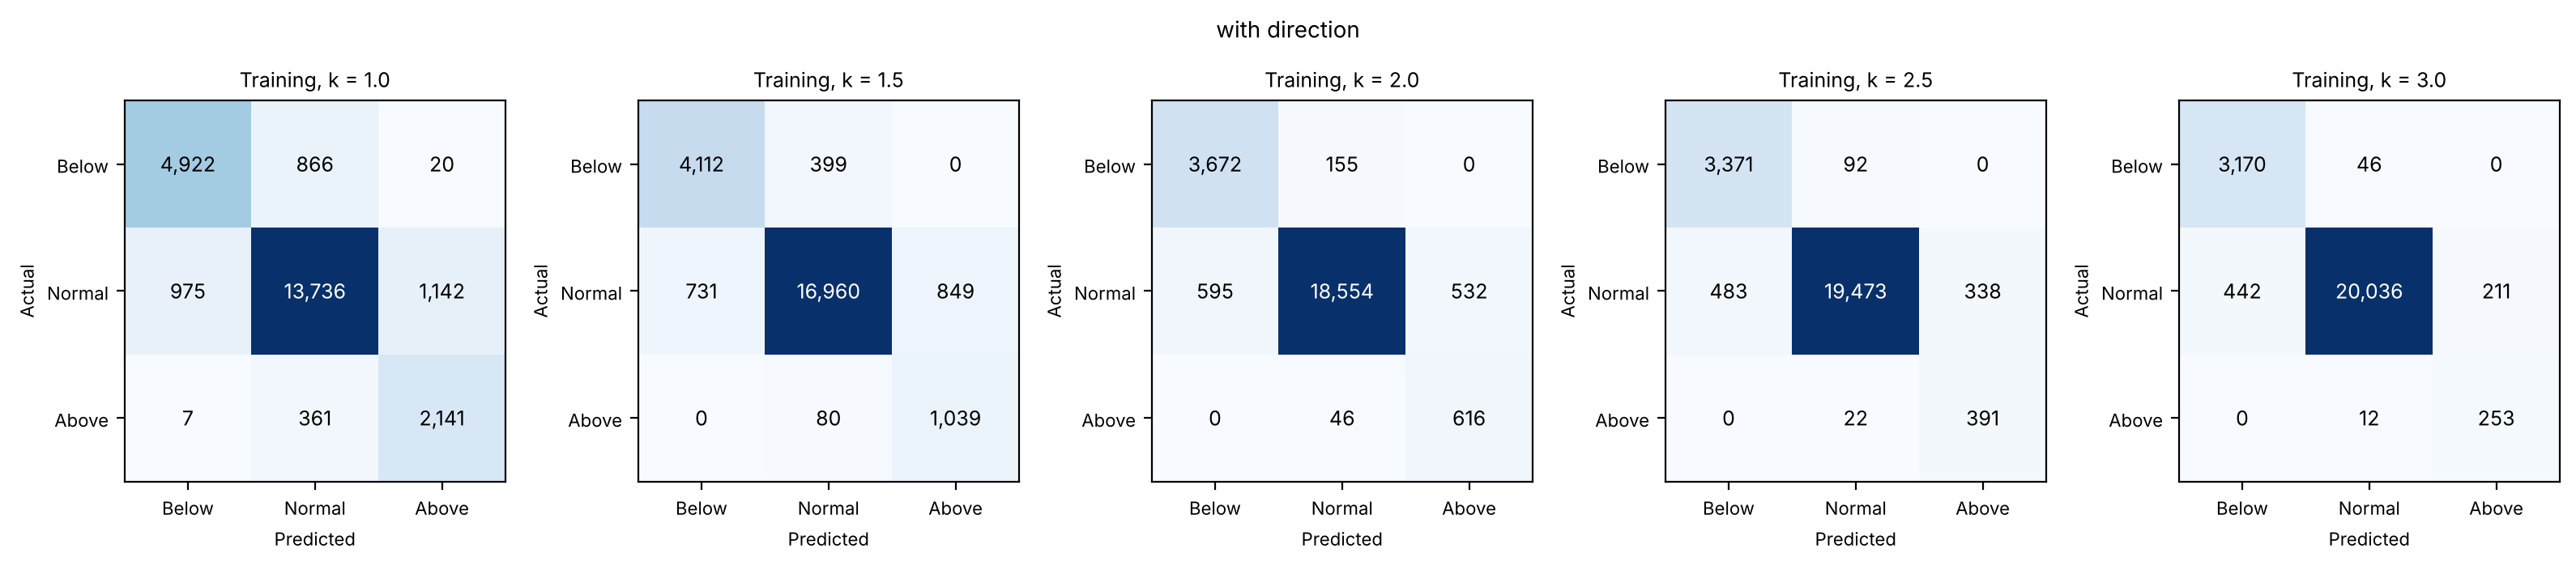

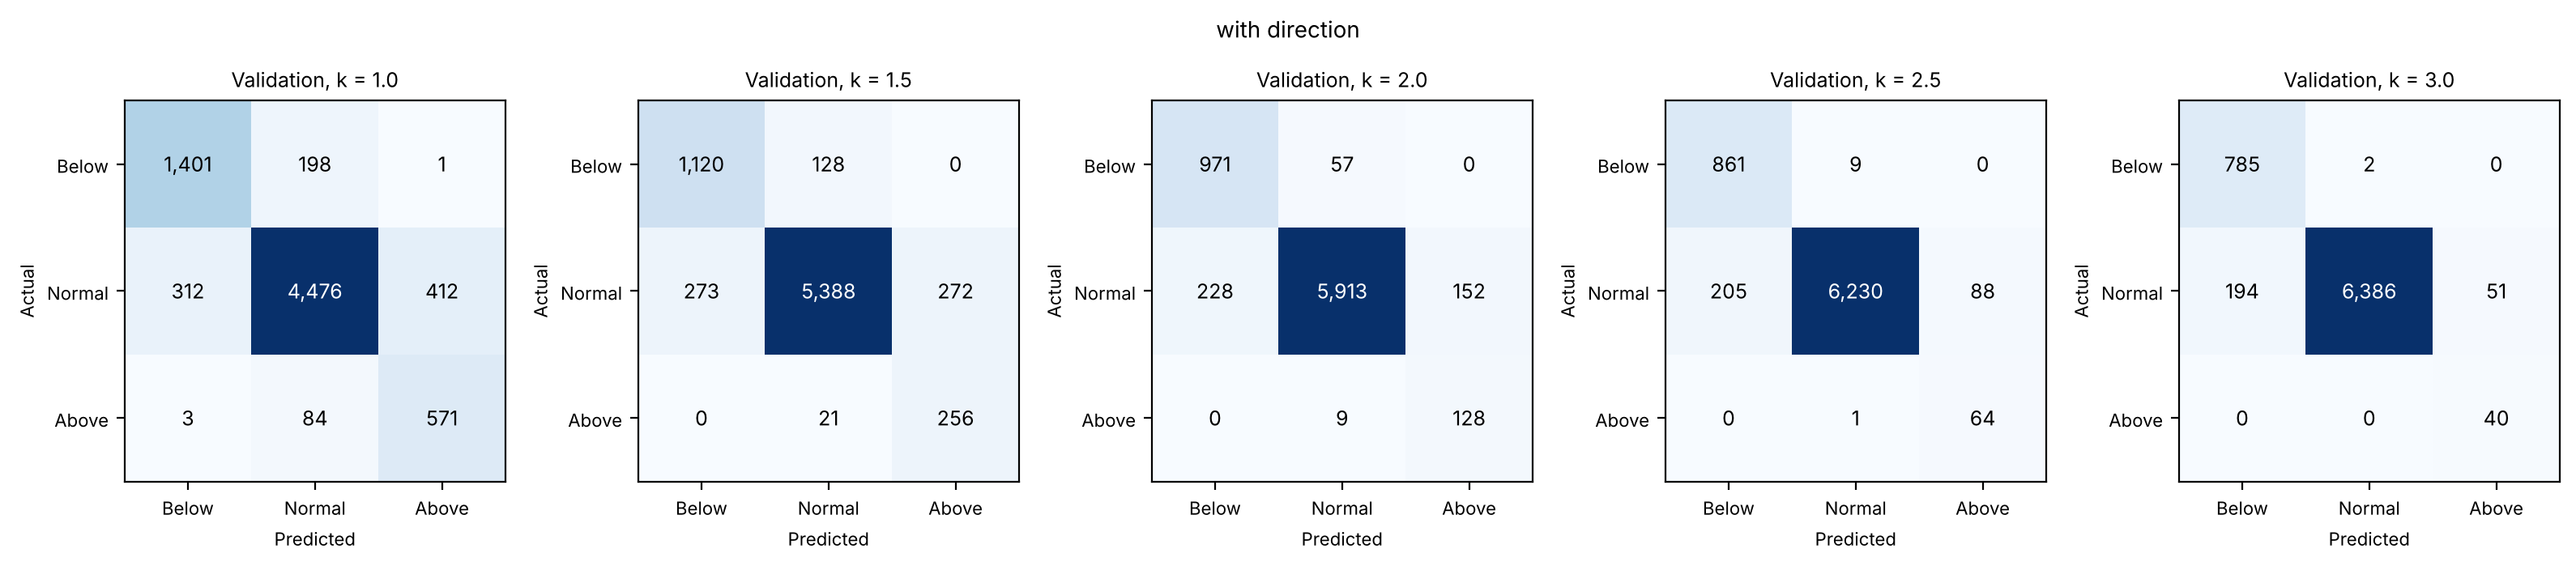

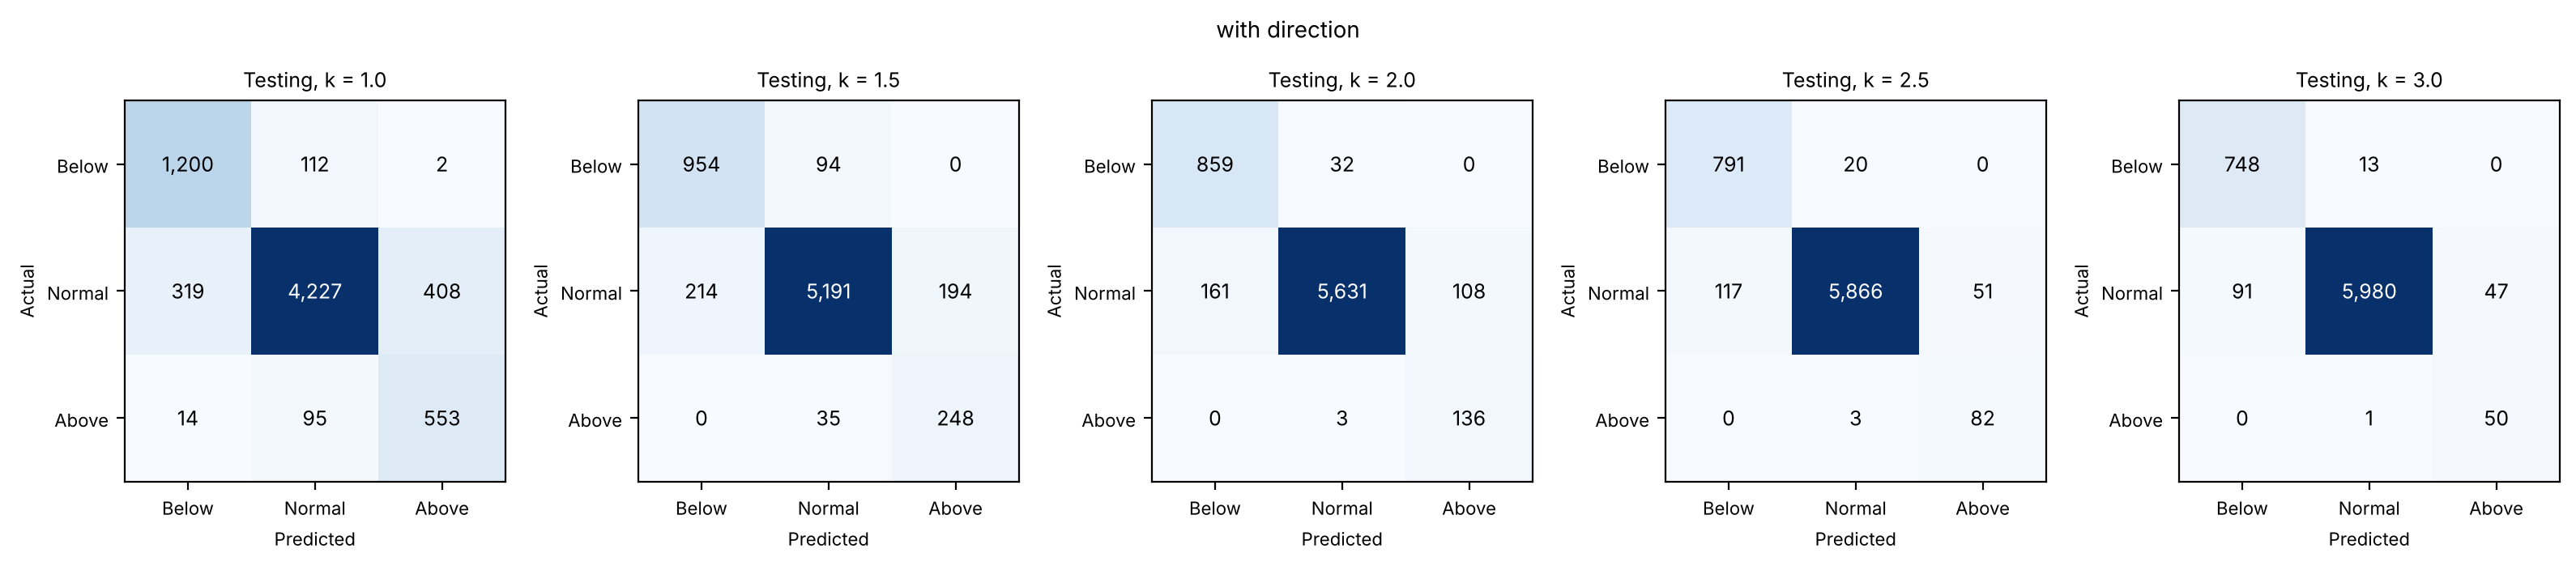


Best k (with direction) = 3.0 | Training F1 = 0.9059

=== Results with best k (with direction) ===
     Split   k   TP  FP  FN    TN  Wrong_direction  Precision  Recall     F1
  Training 3.0 3423 653  58 20036                0     0.8398  0.9833 0.9059
Validation 3.0  825 245   2  6386                0     0.7710  0.9976 0.8698
   Testing 3.0  798 138  14  5980                0     0.8526  0.9828 0.9130


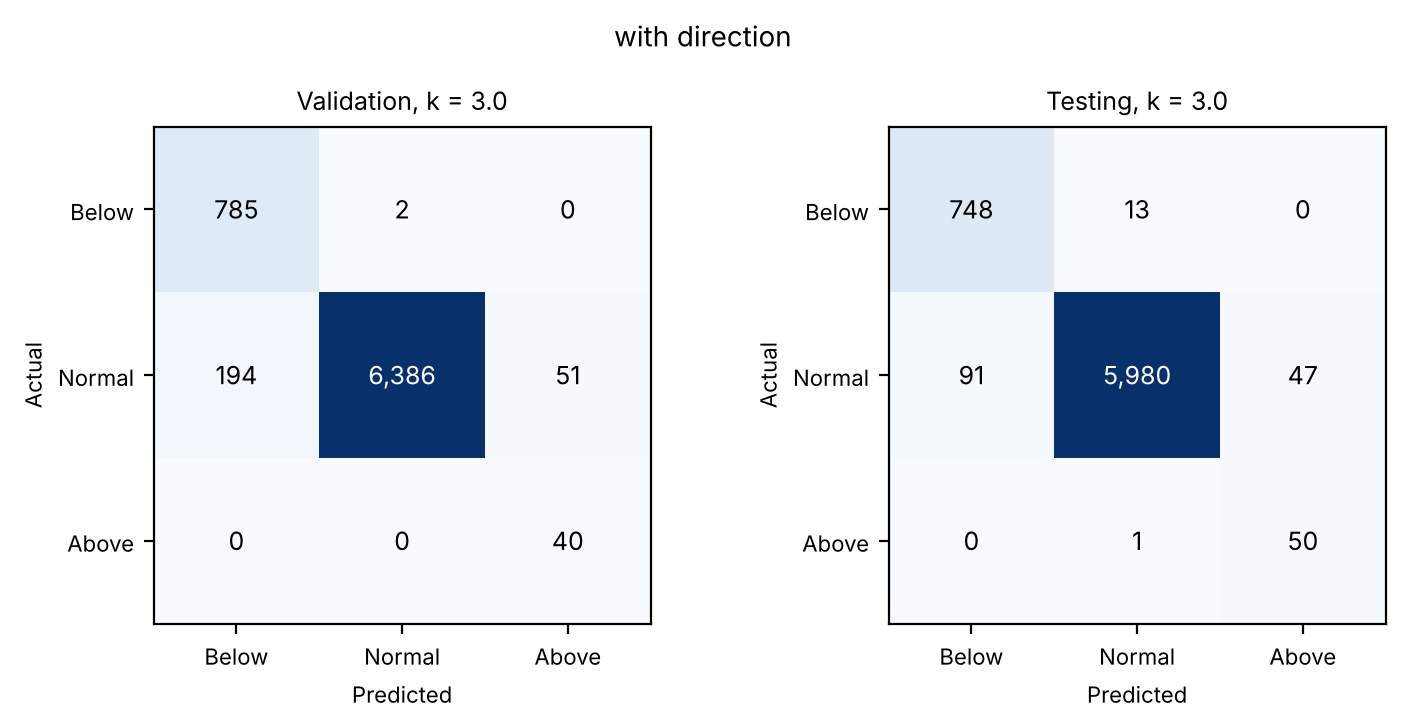

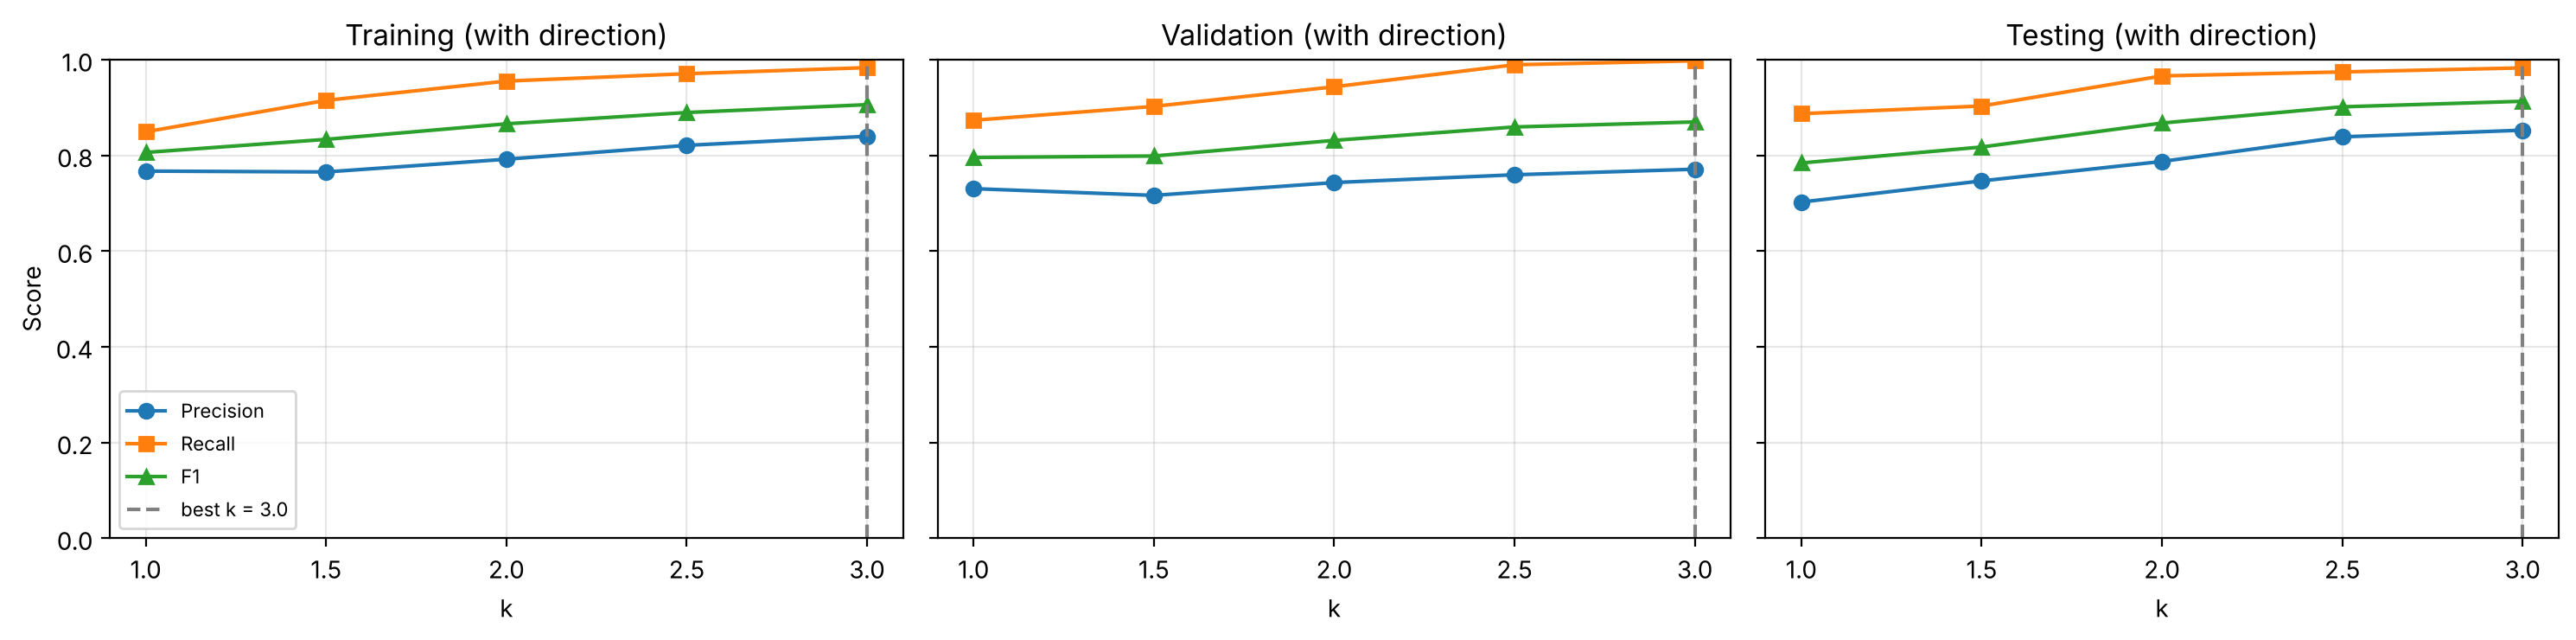

In [4]:
best_k_B, results_B = run_evaluation(direction=True, folder=os.path.join(OUT_DIR, 'B_direction'))

## Results per plant (Version A, best k)

In [5]:
rows = []
for s in splits:
    for plant, g in data[s].groupby('PLANT_ID'):
        r = evaluate(g, best_k_A); r.update({'Split': names[s], 'PLANT_ID': plant}); rows.append(r)
per_plant = pd.DataFrame(rows)[['Split', 'PLANT_ID', 'k', 'TP', 'FP', 'FN', 'TN', 'Precision', 'Recall', 'F1']]
per_plant.to_csv(os.path.join(OUT_DIR, 'A_plain', 'results_best_k_per_plant.csv'), index=False)
per_plant

,Split,PLANT_ID,k,TP,FP,FN,TN,Precision,Recall,F1
0,Training,4135001,3.0,505,305,47,9011,0.6235,0.9149,0.7416
1,Training,4136001,3.0,2918,348,11,11025,0.8934,0.9962,0.9421
2,Validation,4135001,3.0,89,88,1,3716,0.5028,0.9889,0.6667
3,Validation,4136001,3.0,736,157,1,2670,0.8242,0.9986,0.9031
4,Testing,4135001,3.0,100,63,10,3039,0.6135,0.9091,0.7326
5,Testing,4136001,3.0,698,75,4,2941,0.9030,0.9943,0.9464


## Experiment 1 — Train the LSTM on healthy readings only, or on all readings (faults included)?

Everything is the same (windows, model, seed, anomaly rule, ground truth, k values, readings); only the
training data of the LSTM differs. For each model the best k is chosen on Training, as in the main workflow.

In [6]:
EXP_DIR = os.path.join(OUT_DIR, 'experiments')
rows = []
for line, label in [('pred', 'Healthy readings only (main)'), ('pred_all', 'All readings, faults included')]:
    for s in splits:
        for k in k_values:
            r = evaluate(data[s], k, line=line); r.update({'LSTM trained on': label, 'Split': names[s]}); rows.append(r)
exp1_all_k = pd.DataFrame(rows)
exp1_all_k.to_csv(os.path.join(EXP_DIR, 'exp1_training_data_all_k.csv'), index=False)

best = {}
for label, g in exp1_all_k.groupby('LSTM trained on'):
    tr = g[g['Split'] == 'Training']
    best[label] = tr.loc[tr['F1'].idxmax(), 'k']
exp1 = exp1_all_k[exp1_all_k.apply(lambda r: r['k'] == best[r['LSTM trained on']], axis=1)].reset_index(drop=True)

# per plant, at each model's best k
rows = []
for line, label in [('pred', 'Healthy readings only (main)'), ('pred_all', 'All readings, faults included')]:
    for s in splits:
        for plant, g in data[s].groupby('PLANT_ID'):
            rows.append({'LSTM trained on': label, 'Split': names[s], 'PLANT_ID': plant,
                         'F1': evaluate(g, best[label], line=line)['F1']})
exp1_plant = pd.DataFrame(rows).pivot_table(index=['LSTM trained on', 'PLANT_ID'], columns='Split', values='F1')[['Training', 'Validation', 'Testing']]
exp1.to_csv(os.path.join(EXP_DIR, 'exp1_training_data_best_k.csv'), index=False)
exp1_plant.to_csv(os.path.join(EXP_DIR, 'exp1_training_data_per_plant.csv'))
display(exp1[['LSTM trained on', 'Split', 'k', 'TP', 'FP', 'FN', 'TN', 'Precision', 'Recall', 'F1']])
exp1_plant.round(3)

,LSTM trained on,Split,k,TP,FP,FN,TN,Precision,Recall,F1
0,Healthy readings only (main),Training,3.0,3423,653,58,20036,0.8398,0.9833,0.9059
1,Healthy readings only (main),Validation,3.0,825,245,2,6386,0.7710,0.9976,0.8698
2,Healthy readings only (main),Testing,3.0,798,138,14,5980,0.8526,0.9828,0.9130
3,"All readings, faults included",Training,2.5,2639,866,1237,19428,0.7529,0.6809,0.7151
4,"All readings, faults included",Validation,2.5,558,166,377,6357,0.7707,0.5968,0.6727
5,"All readings, faults included",Testing,2.5,665,84,231,5950,0.8879,0.7422,0.8085


Split                                   Training  Validation  Testing
LSTM trained on               PLANT_ID                               
All readings, faults included 4135001      0.698       0.712    0.729
                              4136001      0.720       0.664    0.829
Healthy readings only (main)  4135001      0.742       0.667    0.733
                              4136001      0.942       0.903    0.946

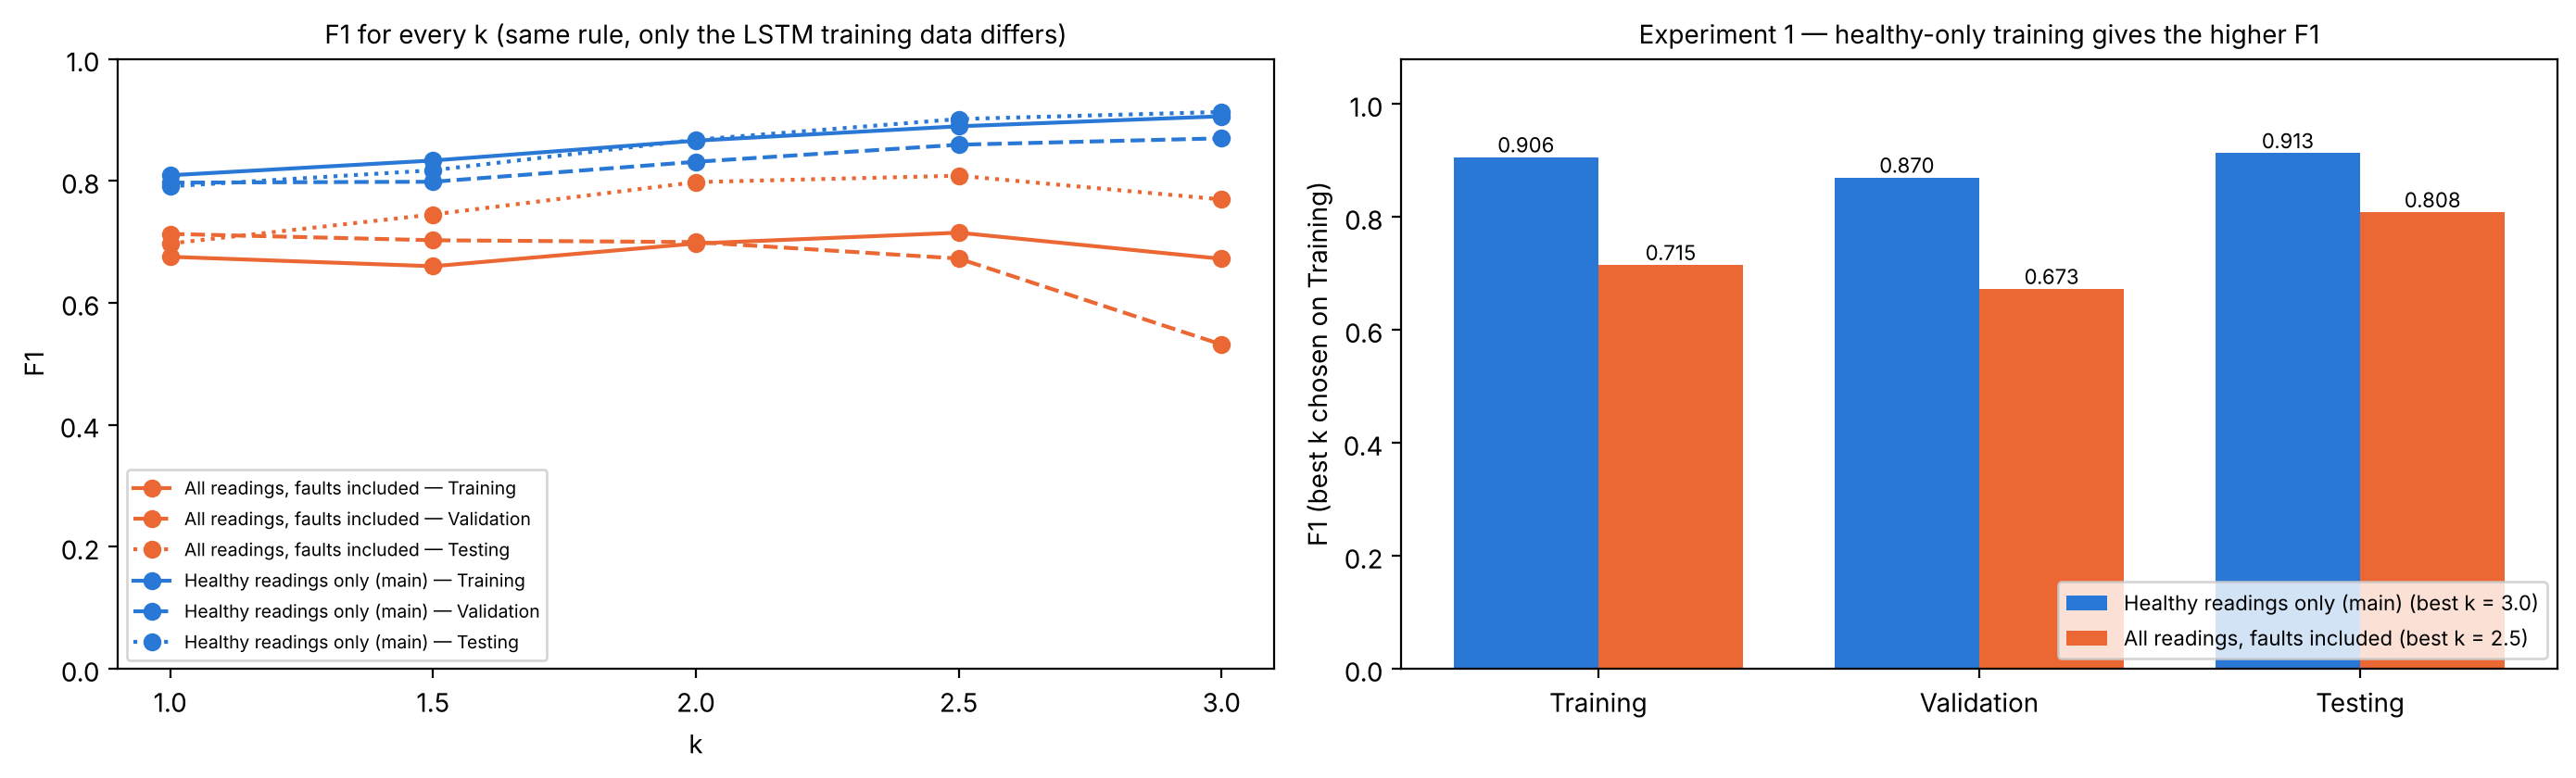

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
colors = {'Healthy readings only (main)': '#2a78d6', 'All readings, faults included': '#eb6834'}
for label, g in exp1_all_k.groupby('LSTM trained on'):
    for s, ls in zip(['Training', 'Validation', 'Testing'], ['-', '--', ':']):
        gg = g[g['Split'] == s]
        axes[0].plot(gg['k'], gg['F1'], ls, marker='o', color=colors[label], label=f'{label} — {s}')
axes[0].set_xticks(k_values); axes[0].set_xlabel('k'); axes[0].set_ylabel('F1'); axes[0].set_ylim(0, 1)
axes[0].set_title('F1 for every k (same rule, only the LSTM training data differs)', fontsize=10)
axes[0].legend(fontsize=7)
x = np.arange(3)
for i, (label, g) in enumerate(exp1.groupby('LSTM trained on', sort=False)):
    vals = g.set_index('Split').loc[['Training', 'Validation', 'Testing'], 'F1'].values
    bars = axes[1].bar(x + (i - 0.5) * 0.38, vals, 0.38, color=colors[label], label=f'{label} (best k = {best[label]})')
    axes[1].bar_label(bars, fmt='%.3f', fontsize=8)
axes[1].set_xticks(x); axes[1].set_xticklabels(['Training', 'Validation', 'Testing'])
axes[1].set_ylim(0, 1.08); axes[1].set_ylabel('F1 (best k chosen on Training)')
axes[1].set_title('Experiment 1 — healthy-only training gives the higher F1', fontsize=10); axes[1].legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig(os.path.join(EXP_DIR, 'exp1_training_data.png'), dpi=150, bbox_inches='tight'); plt.show()

### Independent check on real outages (does not use the physical formula or the k rule)

**Peer-confirmed outage** = the inverter gives ≤ 5 % of the median power of the other inverters of its plant at the
same moment, while those give more than 100 kW (and irradiation ≥ 0.2). How many of them does each LSTM flag?

In [8]:
rows = []
for s in splits:
    d = data[s]
    outage = (d['ACTUAL_AC_POWER_kW'] <= 0.05 * d['PEER_MEDIAN_kW']) & (d['PEER_MEDIAN_kW'] > 100)
    for line, label in [('actual', 'Actual 0/1 (ground truth)'), ('pred', 'LSTM healthy only (main)'), ('pred_all', 'LSTM all readings')]:
        k = best_k_A if line != 'pred_all' else best['All readings, faults included']
        rows.append({'Split': names[s], 'Line': label, 'k': k, 'peer-confirmed outage readings': int(outage.sum()),
                     'flagged': int(d.loc[outage, f'{line}_anomaly_k{k}'].sum())})
outage_check = pd.DataFrame(rows)
outage_check['share flagged'] = (outage_check['flagged'] / outage_check['peer-confirmed outage readings']).round(3)
outage_check.to_csv(os.path.join(EXP_DIR, 'outage_check.csv'), index=False)
outage_check

,Split,Line,k,peer-confirmed outage readings,flagged,share flagged
0,Training,Actual 0/1 (ground truth),3.0,2093,2089,0.998
1,Training,LSTM healthy only (main),3.0,2093,2093,1.000
2,Training,LSTM all readings,2.5,2093,1757,0.839
3,Validation,Actual 0/1 (ground truth),3.0,429,429,1.000
4,Validation,LSTM healthy only (main),3.0,429,429,1.000
5,Validation,LSTM all readings,2.5,429,316,0.737
6,Testing,Actual 0/1 (ground truth),3.0,455,455,1.000
7,Testing,LSTM healthy only (main),3.0,455,454,0.998
8,Testing,LSTM all readings,2.5,455,435,0.956


### Why the neighbours are not used as the ground truth

A natural alternative reference is the median of the other inverters of the plant (peer comparison, as in SolarClique,
Iyengar et al. 2018). In plant 4136001 many inverters are often down at the same moment, which pulls that median down,
so healthy inverters look "too high". We count how often this happens.

In [9]:
d = pd.concat([data[s] for s in splits])
d2 = d[d['PLANT_ID'] == 4136001].copy()
d2['down'] = d2['ACTUAL_AC_POWER_kW'] <= 0.05 * d2['EXPECTED_PHYS_kW']
d2['n_down'] = d2.groupby('DATE_TIME')['down'].transform('sum')
high = d2['ACTUAL_AC_POWER_kW'] > 1.2 * d2['PEER_MEDIAN_kW']
peer_note = pd.Series({
    'plant-2 readings > 120 % of the neighbours\' median': int(high.sum()),
    'median no. of plant-2 inverters down at those moments': float(d2.loc[high, 'n_down'].median()),
    'median no. of plant-2 inverters down at other moments': float(d2.loc[~high, 'n_down'].median()),
    'median actual / LSTM (healthy) for those readings': round(float((d2.loc[high, 'ACTUAL_AC_POWER_kW'] / d2.loc[high, 'PREDICTED_AC_POWER_kW']).median()), 3),
})
peer_note.to_csv(os.path.join(EXP_DIR, 'peer_reference_problem.csv'), header=['value'])
peer_note

plant-2 readings > 120 % of the neighbours' median       890.000
median no. of plant-2 inverters down at those moments      8.000
median no. of plant-2 inverters down at other moments      0.000
median actual / LSTM (healthy) for those readings          1.045
dtype: float64

## Experiment 2 — Why the previous rules gave a low F1

The previous version used the LSTM trained on all readings and applied a rule to **each power line alone**:
- **Rule 1 (Notebook 3 before):** change from the previous reading outside mean ± k·std of all previous changes.
- **Rule 2 (report k = 1):** power outside mean ± k·std of the same 15-minute slot on the training days.

We recompute both on the same readings and count the peer-confirmed outages (definition above): how many are
in each rule's ground truth (Actual 0/1), and how many its predicted line finds.

In [10]:
def change_rule(series, k, min_history=10):
    '''Rule 1 (previous Notebook 3), vectorised: same result as the loop version.'''
    x = pd.Series(np.asarray(series, float)).diff().fillna(0)
    mean_past = x.expanding().mean().shift(1)
    std_past = x.expanding().std(ddof=0).shift(1)
    out = ((x > mean_past + k * std_past) | (x < mean_past - k * std_past)).astype(int)
    zero = std_past == 0
    out[zero] = (x[zero] != mean_past[zero]).astype(int)
    out[:min_history] = 0
    return out.values

prev = {s: full[s].sort_values(['SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True) for s in splits}
# the previous version used the raw (unclipped) predictions of the LSTM trained on all readings
PREV_PRED = 'PREDICTED_ALL_DATA_RAW_kW' if 'PREDICTED_ALL_DATA_RAW_kW' in prev['train'] else 'PREDICTED_ALL_DATA_kW'
for s in splits:
    prev[s]['SLOT'] = prev[s]['DATE_TIME'].dt.strftime('%H:%M')
slot_stats = {col: prev['train'].groupby(['SOURCE_KEY', 'SLOT'])[col].agg(['mean', 'std'])
              for col in ['ACTUAL_AC_POWER_kW', PREV_PRED]}
for s in splits:
    d = prev[s]
    for k in k_values:
        for col, tag in [('ACTUAL_AC_POWER_kW', 'a'), (PREV_PRED, 'p')]:
            d[f'r1{tag}_{k}'] = np.concatenate([change_rule(g.values, k) for _, g in d.groupby('SOURCE_KEY', sort=False)[col]])
            st = d[['SOURCE_KEY', 'SLOT']].merge(slot_stats[col].reset_index(), on=['SOURCE_KEY', 'SLOT'], how='left')
            d[f'r2{tag}_{k}'] = ((d[col] - st['mean']).abs() > k * st['std']).astype(int).values

def f1_of(a, p):
    tp, fp, fn = ((a == 1) & (p == 1)).sum(), ((a == 0) & (p == 1)).sum(), ((a == 1) & (p == 0)).sum()
    P = tp / (tp + fp) if tp + fp else 0; R = tp / (tp + fn) if tp + fn else 0
    return round(2 * P * R / (P + R), 4) if P + R else 0

rows = []
for rule, label in [('r1', 'Rule 1: change from previous reading (each line alone)'),
                    ('r2', 'Rule 2: usual power at this time of day (each line alone)')]:
    bk = max(k_values, key=lambda k: f1_of(prev['train'][f'{rule}a_{k}'], prev['train'][f'{rule}p_{k}']))
    for s in splits:
        d = prev[s]
        outage = (d['ACTUAL_AC_POWER_kW'] <= 0.05 * d['PEER_MEDIAN_kW']) & (d['PEER_MEDIAN_kW'] > 100) & (d['IRRADIATION'] >= 0.2)
        rows.append({'Definition': label, 'best k': bk, 'Split': names[s], 'F1': f1_of(d[f'{rule}a_{bk}'], d[f'{rule}p_{bk}']),
                     'outage readings': int(outage.sum()), 'in Actual 0/1': int(d.loc[outage, f'{rule}a_{bk}'].sum()),
                     'found by Predicted 0/1': int(d.loc[outage, f'{rule}p_{bk}'].sum())})
for s in splits:
    d = data[s]
    outage = (d['ACTUAL_AC_POWER_kW'] <= 0.05 * d['PEER_MEDIAN_kW']) & (d['PEER_MEDIAN_kW'] > 100)
    rows.append({'Definition': 'NEW: actual − expected power (PVWatts / LSTM healthy)', 'best k': best_k_A, 'Split': names[s],
                 'F1': evaluate(d, best_k_A)['F1'], 'outage readings': int(outage.sum()),
                 'in Actual 0/1': int(d.loc[outage, f'actual_anomaly_k{best_k_A}'].sum()),
                 'found by Predicted 0/1': int(d.loc[outage, f'pred_anomaly_k{best_k_A}'].sum())})
exp2 = pd.DataFrame(rows)
exp2.to_csv(os.path.join(EXP_DIR, 'exp2_previous_rules.csv'), index=False)
exp2

,Definition,best k,Split,F1,outage readings,in Actual 0/1,found by Predicted 0/1
0,Rule 1: change from previous reading (each lin...,1.0,Training,0.6204,2093,164,239
1,Rule 1: change from previous reading (each lin...,1.0,Validation,0.6304,429,40,125
2,Rule 1: change from previous reading (each lin...,1.0,Testing,0.7315,455,40,130
3,Rule 2: usual power at this time of day (each ...,1.0,Training,0.6461,2093,1304,302
4,Rule 2: usual power at this time of day (each ...,1.0,Validation,0.6868,429,253,50
5,Rule 2: usual power at this time of day (each ...,1.0,Testing,0.5925,455,401,178
6,NEW: actual − expected power (PVWatts / LSTM h...,3.0,Training,0.9059,2093,2089,2093
7,NEW: actual − expected power (PVWatts / LSTM h...,3.0,Validation,0.8698,429,429,429
8,NEW: actual − expected power (PVWatts / LSTM h...,3.0,Testing,0.9130,455,455,454


Note: the F1 values of the three rows are not directly comparable, because each rule has its own ground truth.
What the table shows is *what* each ground truth contains: Rule 1 hardly contains the outages at all (only the
moment of the drop), Rule 2 contains them but its predicted line cannot see them (the LSTM line follows the
weather), and the new rule contains them and finds them.

## Fault events (Version A, best k)

An **event** = consecutive readings of one inverter, on one day, with Actual = 1. An event is **found** if the
Predicted 0/1 has at least one 1 inside it. Both LSTMs use the main best k, so they are scored on the same events.

In [11]:
def events(df, line, k):
    rows = []
    for (inv, day), g in df.groupby(['SOURCE_KEY', df['DATE_TIME'].dt.date]):
        a = g[f'actual_anomaly_k{k}'].values; p = g[f'{line}_anomaly_k{k}'].values
        run_id = np.cumsum(np.r_[1, np.diff(a) != 0])
        for rid in np.unique(run_id[a == 1]):
            m = run_id == rid
            rows.append({'readings': int(m.sum()), 'found': bool(p[m].any())})
    return pd.DataFrame(rows)

rows = []
for s in splits:
    for line, label in [('pred', 'LSTM healthy only (main)'), ('pred_all', 'LSTM all readings')]:
        k = best_k_A                      # same k for both, so both are scored on the same events
        ev = events(data[s], line, k)
        long_ev = ev[ev['readings'] >= 4]
        rows.append({'Split': names[s], 'LSTM': label, 'k': k, 'events': len(ev), 'found': int(ev['found'].sum()),
                     'events >= 1 hour': len(long_ev), 'found (>= 1 hour)': int(long_ev['found'].sum())})
event_table = pd.DataFrame(rows)
event_table.to_csv(os.path.join(EXP_DIR, 'fault_events.csv'), index=False)
event_table

,Split,LSTM,k,events,found,events >= 1 hour,found (>= 1 hour)
0,Training,LSTM healthy only (main),3.0,880,841,195,195
1,Training,LSTM all readings,3.0,880,525,195,159
2,Validation,LSTM healthy only (main),3.0,264,263,46,46
3,Validation,LSTM all readings,3.0,264,129,46,35
4,Testing,LSTM healthy only (main),3.0,231,221,37,37
5,Testing,LSTM all readings,3.0,231,133,37,35


## Sensitivity check — do the fixed settings change the conclusion?

The main LSTM is kept; only one setting of the rule changes at a time. Best k is chosen on Training each time.
- temperature coefficient γ of the physical formula: −0.47 %/°C (PVWatts v5 standard), −0.37 %/°C, 0 (no correction)
- irradiance limit for evaluated readings: 0.1, 0.2, 0.3 kW/m²
- μ and σ = mean and standard deviation (classic) instead of median and 1.4826·MAD

In [12]:
def run_variant(gamma=-0.0047, irr_min=0.2, robust=True):
    rows = {}
    base = {s: full[s].copy() for s in splits}
    tf_ = {s: 1 + gamma * (base[s]['MODULE_TEMPERATURE'] - 25) for s in splits}
    cal = base['train'][base['train']['IRRADIATION'] >= irr_min]
    p_ref = (cal['ACTUAL_AC_POWER_kW'] / (cal['IRRADIATION'] * tf_['train'][cal.index])).groupby(cal['SOURCE_KEY']).median()
    est = (lambda x: (np.median(x), 1.4826 * np.median(np.abs(x - np.median(x))))) if robust else (lambda x: (np.mean(x), np.std(x)))
    for s in splits:
        d = base[s]
        d['ra'] = d['ACTUAL_AC_POWER_kW'] - d['SOURCE_KEY'].map(p_ref) * d['IRRADIATION'] * tf_[s]
        d['rp'] = d['ACTUAL_AC_POWER_kW'] - d['PREDICTED_AC_POWER_kW']
        base[s] = d[d['IRRADIATION'] >= irr_min]
    t = base['train']
    lim = {c: pd.DataFrame({inv: est(g.values) for inv, g in t.groupby('SOURCE_KEY')[c]}, index=['mu', 'sd']).T for c in ['ra', 'rp']}
    for k in k_values:
        for s in splits:
            d = base[s]; f = {}
            for c in ['ra', 'rp']:
                mu, sd = d['SOURCE_KEY'].map(lim[c]['mu']), d['SOURCE_KEY'].map(lim[c]['sd'])
                f[c] = ((d[c] - mu).abs() > k * sd).astype(int).values
            rows[(s, k)] = f1_of(f['ra'], f['rp'])
    bk = max(k_values, key=lambda k: rows[('train', k)])
    return {'best k': bk, 'Training': rows[('train', bk)], 'Validation': rows[('val', bk)], 'Testing': rows[('test', bk)]}

variants = [('main: γ = −0.47 %/°C, G ≥ 0.2, median/MAD', {}),
            ('γ = −0.37 %/°C', {'gamma': -0.0037}), ('γ = 0 (no temperature correction)', {'gamma': 0.0}),
            ('G ≥ 0.1 kW/m²', {'irr_min': 0.1}), ('G ≥ 0.3 kW/m²', {'irr_min': 0.3}),
            ('mean and std instead of median/MAD', {'robust': False})]
sensitivity = pd.DataFrame([{'Variant': n, **run_variant(**kw)} for n, kw in variants])
sensitivity.to_csv(os.path.join(EXP_DIR, 'sensitivity.csv'), index=False)
sensitivity

,Variant,best k,Training,Validation,Testing
0,"main: γ = −0.47 %/°C, G ≥ 0.2, median/MAD",3.0,0.9074,0.8677,0.9147
1,γ = −0.37 %/°C,3.0,0.9113,0.8763,0.9090
2,γ = 0 (no temperature correction),3.0,0.8977,0.8707,0.8897
3,G ≥ 0.1 kW/m²,3.0,0.8984,0.8659,0.9092
4,G ≥ 0.3 kW/m²,3.0,0.9100,0.8565,0.9093
5,mean and std instead of median/MAD,1.5,0.9144,0.9001,0.9267


γ and the irradiance limit change F1 only in the second decimal, so the conclusion does not depend on them.
(The "main" row differs from the official result in the 3rd decimal because P_ref is re-fitted here on the windowed
readings only.) The classic **mean/std** scores a little higher; the next cell shows why: its σ is inflated by the
outages of plant 4136001, so its ground truth keeps the outages but drops most partial power losses.

In [13]:
tr_e, te_e = data['train'], data['test']
ms = tr_e.groupby('SOURCE_KEY')['RESID_ACTUAL_kW'].agg(['mean', 'std'])
k_ms = sensitivity.loc[sensitivity['Variant'].str.startswith('mean'), 'best k'].iloc[0]
gt_ms = (te_e['RESID_ACTUAL_kW'] - te_e['SOURCE_KEY'].map(ms['mean'])).abs() > k_ms * te_e['SOURCE_KEY'].map(ms['std'])
gt_rb = te_e[f'actual_anomaly_k{best_k_A}'] == 1
outage = (te_e['ACTUAL_AC_POWER_kW'] <= 0.05 * te_e['PEER_MEDIAN_kW']) & (te_e['PEER_MEDIAN_kW'] > 100)
partial = (te_e['ACTUAL_AC_POWER_kW'] < 0.8 * te_e['EXPECTED_PHYS_kW']) & ~outage
robust_vs_classic = pd.DataFrame({
    f'median / MAD, k = {best_k_A:g} (main)': [int(gt_rb.sum()), int(gt_rb[outage].sum()), int(gt_rb[partial].sum())],
    f'mean / std, k = {k_ms:g}': [int(gt_ms.sum()), int(gt_ms[outage].sum()), int(gt_ms[partial].sum())]},
    index=['test readings in Actual 0/1', f'… of the {int(outage.sum())} outage readings',
           f'… of the {int(partial.sum())} partial-loss readings (< 80 % of PVWatts, not an outage)'])
robust_vs_classic.to_csv(os.path.join(EXP_DIR, 'robust_vs_classic_ground_truth.csv'))
print('std of the actual-line residual on training days, median over inverters (kW):',
      tr_e.groupby('SOURCE_KEY')['RESID_ACTUAL_kW'].std().groupby(tr_e.groupby('SOURCE_KEY')['PLANT_ID'].first()).median().round(0).to_dict())
robust_vs_classic

std of the actual-line residual on training days, median over inverters (kW): {4135001: 78.0, 4136001: 396.0}


,"median / MAD, k = 3 (main)","mean / std, k = 1.5"
test readings in Actual 0/1,812,650
… of the 455 outage readings,455,362
"… of the 356 partial-loss readings (< 80 % of PVWatts, not an outage)",276,111


With mean/std the plant-2 limits are several times wider than plant 1's, so a partial loss of 20–50 % is "normal"
there. Both lines then only flag the gross outages, which are easy to agree on — a higher F1, but a weaker detector.
We keep median/MAD, as recommended by Leys et al. (2013) and, for PV arrays, Zhao et al. (2013).

## Save outputs

In [14]:
zip_path = shutil.make_archive(OUT_DIR, 'zip', OUT_DIR)
for folder in ['A_plain', 'B_direction', 'experiments']:
    print(folder, sorted(os.listdir(os.path.join(OUT_DIR, folder))))
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('Saved to', zip_path)

A_plain ['best_k.txt', 'confusion_matrices_best_k_val_test.png', 'confusion_matrices_test.png', 'confusion_matrices_train.png', 'confusion_matrices_val.png', 'metrics_all_k.csv', 'metrics_vs_k.png', 'results_best_k.csv', 'results_best_k_per_plant.csv']
B_direction ['best_k.txt', 'confusion_matrices_best_k_val_test.png', 'confusion_matrices_test.png', 'confusion_matrices_train.png', 'confusion_matrices_val.png', 'metrics_all_k.csv', 'metrics_vs_k.png', 'results_best_k.csv']
experiments ['exp1_training_data.png', 'exp1_training_data_all_k.csv', 'exp1_training_data_best_k.csv', 'exp1_training_data_per_plant.csv', 'exp2_previous_rules.csv', 'fault_events.csv', 'outage_check.csv', 'peer_reference_problem.csv', 'robust_vs_classic_ground_truth.csv', 'sensitivity.csv']
Saved to /home/user/SUNSHIELD/outputs/step4_outputs.zip
